# Cuba hydrography map

Combine Cuba’s published **river and channel centerlines**, **water-body polygons**,
**land polygons** and **coastline** to draw a national hydrography map. River lines
are graded by Strahler orders **3–7**; lakes, reservoirs, lagoons and other mapped
water bodies provide the surface-water layer.

Open this notebook from a local copy of the repository and run the cells in order
using **Pandas**, **GeoPandas**, **PyArrow** and **Matplotlib**. Set the working directory to
`examples/`. All layers are loaded locally; no online basemap is required.


## Load the data

Read the published GeoParquet files:

- [River centerlines](../data/river-centerlines/) describe modelled drainage paths. Lines represent courses, rather than river width or banks.
- [River catchments](../data/river-catchments/) associate water-body outlet locations with drainage systems. The compressed GeoParquet file is read through Python’s `gzip` module.
- [Water-body geometry](../data/water-body-geometry/) supplies polygon outlines for mapped standing-water features.
- [Land polygons](../data/land-polygons/) provide the background land area, including islands and keys present in the product.
- [Coastline](../data/coastline/) supplies the line separating land and sea.

GeoParquet preserves each layer’s geometry and coordinate reference system.
These products use **EPSG:4326**, WGS 84 longitude and latitude in degrees.

Geometry and names are separate products. To retrieve a preferred name, join a
geometry record’s `gazetteer_id` to the names dataset’s `id`. Detailed named feature
types are documented in [the water geographic names example](water_geographic_names.ipynb).


In [1]:
from pathlib import Path
import gzip
import json
import pandas as pd
from IPython.display import HTML, display
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path("..")

rivers = gpd.read_parquet(ROOT / "data/river-centerlines/cuba_river_centerlines.parquet")
water_bodies = gpd.read_parquet(ROOT / "data/water-body-geometry/cuba_water_body_geometry.parquet")
land = gpd.read_parquet(ROOT / "data/land-polygons/cuba_land_polygons.parquet")
coastline = gpd.read_parquet(ROOT / "data/coastline/cuba_coastline.parquet")

with gzip.open(ROOT / "data/river-catchments/cuba_river_catchments.parquet.gz", "rb") as file:
    catchments = gpd.read_parquet(file)


## Count hydrographic systems and their names

A **system** comprises a main watercourse and all its connected tributaries and
other associated water features. In this centerline dataset, `MAIN_BAS` identifies
the connected drainage networks represented in this dataset. This includes
small single-reach drainages with no tributaries. It is a count of modelled
drainage networks, rather than an inventory of major named rivers.

The structure table distinguishes single-reach networks, order-2 networks and
networks reaching order 3 or higher. The last group is represented in the map.
Count the full network before selecting
orders for the map, so small branches and small systems remain included.

A system is **named in some way** when at least one reach or associated water body
has a preferred or additional assigned name. That name may belong to a tributary,
canal, ditch, lake, lagoon, reservoir or other linked feature; it does not imply
that every feature in the system shares one name.

Associate each water body through its recorded outlet (`Pour_long`, `Pour_lat`)
and the catchment containing that outlet. An outlet must identify a unique system;
unmatched outlets and outlets on boundaries between different systems remain
unassociated and are reported separately. This avoids assigning a water body to
several systems merely because its polygon crosses their boundaries.

These counts describe the published centerline and water-body coverage. They are
not counts of every water feature that may exist in Cuba.


### Associate features and names

Prepare one naming summary per system and associate water bodies through their outlets.


In [2]:
# Identify preferred or additional assigned names.
def has_assigned_name(frame):
    return frame["gazetteer_id"].notna() | frame["alternative_gazetteer_ids"].map(
        lambda values: bool(json.loads(values))
    )

# Summarize reach names within each complete drainage system.
reach_names = has_assigned_name(rivers)
systems = rivers.assign(named=reach_names).groupby("MAIN_BAS")["named"].any().to_frame("Named reach")

# Associate water bodies by the catchment containing their outlet.
outlets = gpd.GeoDataFrame(
    water_bodies[["id"]].copy(),
    geometry=gpd.points_from_xy(water_bodies["Pour_long"], water_bodies["Pour_lat"]),
    crs=water_bodies.crs,
)
located = gpd.sjoin(outlets, catchments[["MAIN_BAS", "geometry"]], how="left", predicate="intersects")
possible_systems = located.groupby("id")["MAIN_BAS"].agg(
    lambda values: set(values.dropna().astype(int))
)
# Retain an association only when the outlet identifies one system.
body_system = possible_systems.map(lambda values: next(iter(values)) if len(values) == 1 else None)
associated_bodies = water_bodies.assign(
    system=water_bodies["id"].map(body_system),
    named=has_assigned_name(water_bodies),
)
# A system qualifies when a reach or associated water body has a name.
named_bodies = associated_bodies.dropna(subset=["system"]).groupby("system")["named"].any()
systems["Named water body"] = named_bodies.reindex(systems.index, fill_value=False)
systems["Any assigned name"] = systems[["Named reach", "Named water body"]].any(axis=1)


### Systems with assigned names

Count each complete system once, whether its name comes from a reach or an associated water body.


In [3]:
# Count all systems, named systems and systems without assigned names.
system_counts = pd.DataFrame({
    "Modelled drainage systems": ["Total — all orders", "Named in some way", "No assigned names"],
    "Count": [len(systems), int(systems["Any assigned name"].sum()), int((~systems["Any assigned name"]).sum())],
})
display(HTML(system_counts.to_html(index=False)))


Modelled drainage systems,Count
Total — all orders,1999
Named in some way,469
No assigned names,1530


### Network structure

Separate small single-reach drainages from branching networks. Orders 3–7 are the networks represented in the map.


In [4]:
# Classify systems by their highest Strahler order.
highest_order = rivers.groupby("MAIN_BAS")["ORD_STRAH"].max().reindex(systems.index)
structure_groups = {
    "Single-reach drainages (order 1)": highest_order.eq(1),
    "Branching networks (highest order 2)": highest_order.eq(2),
    "Networks reaching orders 3–7": highest_order.ge(3),
}
structure_counts = pd.DataFrame([
    {"Network structure": label, "Total": int(mask.sum()),
     "Named in some way": int(systems.loc[mask, "Any assigned name"].sum())}
    for label, mask in structure_groups.items()
])
display(HTML(structure_counts.to_html(index=False)))


Network structure,Total,Named in some way
Single-reach drainages (order 1),1091,59
Branching networks (highest order 2),469,97
Networks reaching orders 3–7,439,313


### Associated features

Count reaches and uniquely associated water bodies, then show how many have assigned names. Water bodies without a unique system association are reported below the table.


In [5]:
# Count individual features rather than drainage systems.
feature_counts = pd.DataFrame({
    "Associated features": ["River and channel reaches", "Water bodies with a unique system"],
    "Total": [len(rivers), int(associated_bodies["system"].notna().sum())],
    "With an assigned name": [int(reach_names.sum()), int((associated_bodies["system"].notna() & associated_bodies["named"]).sum())],
})
display(HTML(feature_counts.to_html(index=False)))
print(f"Water bodies without a unique system association: {associated_bodies['system'].isna().sum():,}")


Water bodies without a unique system association: 304


Associated features,Total,With an assigned name
River and channel reaches,56594,16802
Water bodies with a unique system,844,308


## Create the map

### Select the river orders

`ORD_STRAH` gives Strahler stream order. Higher orders represent a more developed
branching network. Select orders **3–7** for a readable national view; smaller
branches remain in the source data.

Change `river_orders` below to select a different range, and adjust `widths` in
the plotting cell to give each selected order its line width.


In [6]:
river_orders = [3, 4, 5, 6, 7]
map_rivers = rivers.loc[rivers["ORD_STRAH"].isin(river_orders)]


### Draw the map

Use a subdued land background, blue water-body polygons and progressively thicker
river lines. The coastline is drawn above the water layers. Line thickness shows
stream order, rather than measured river width. No legend is displayed.

Adjust the plotting options below to change colours, line widths or figure size.
Uncomment `fig.savefig(...)` to save the map as `examples/hydrography_map.png`.

For complete systems and contributing watersheds associated with the ONEI river
list, see [the ONEI river systems example](onei_river_systems.ipynb).


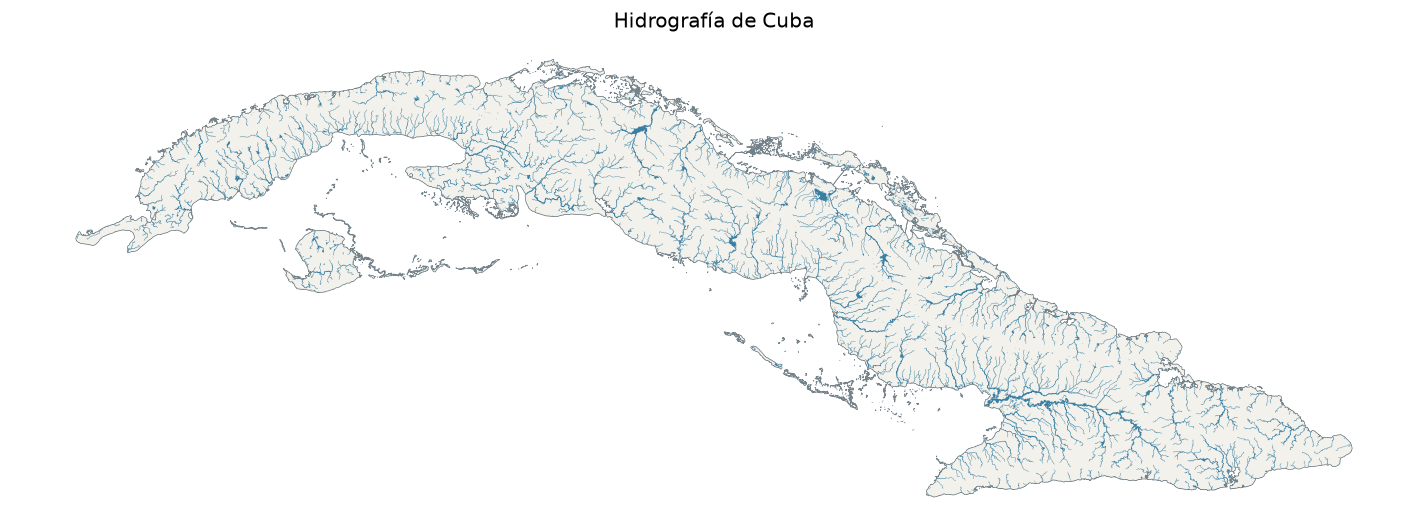

In [7]:
fig, ax = plt.subplots(figsize=(12, 9))

land.plot(ax=ax, color="#F2F1EB", edgecolor="none", zorder=1)
water_bodies.plot(ax=ax, color="#397FA3", edgecolor="none", zorder=2)

widths = {3: 0.20, 4: 0.30, 5: 0.45, 6: 0.65, 7: 0.90}
for order, width in widths.items():
    map_rivers.loc[map_rivers["ORD_STRAH"].eq(order)].plot(
        ax=ax, color="#397FA3", linewidth=width, zorder=3,
    )

coastline.plot(ax=ax, color="#74828A", linewidth=0.35, zorder=4)

ax.set_title("Hidrografía de Cuba")
ax.set_axis_off()
fig.tight_layout()
plt.show()

# to save the map, uncomment the following line
# fig.savefig(ROOT / "examples/hydrography_map.png", dpi=220, bbox_inches="tight")
